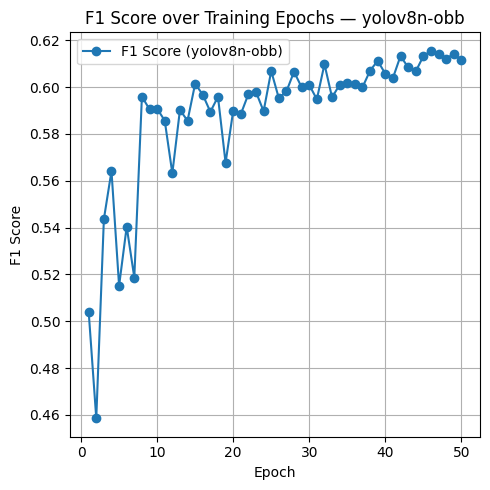

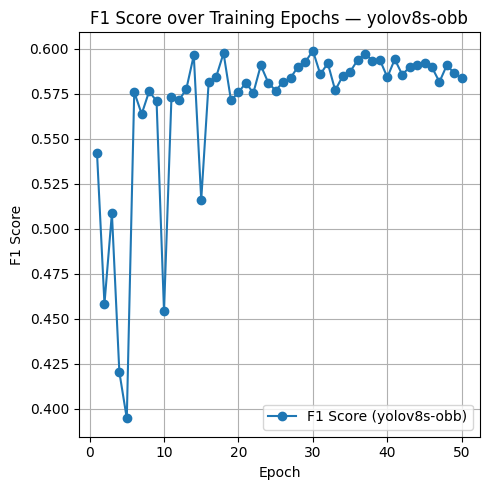

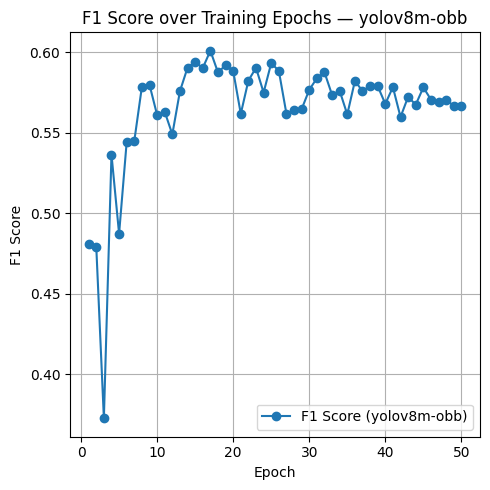

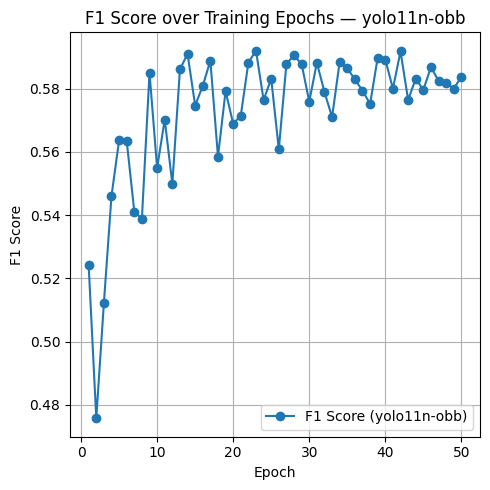

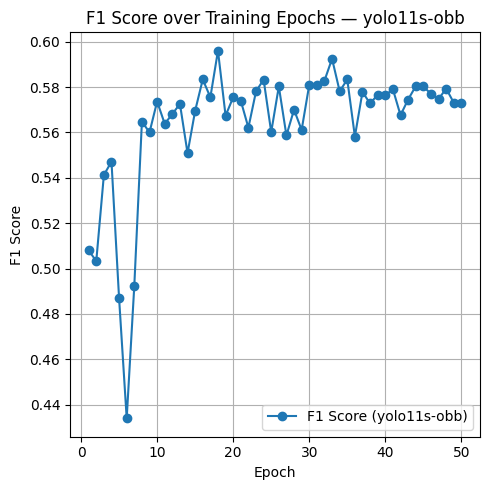

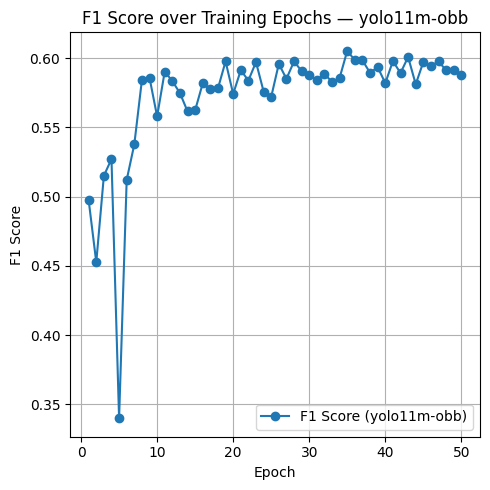

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# List of paths to your results.csv files
csv_paths = [
    "/kaggle/input/rasoul-b-e-s-obb-yolov8n/yolo_training_results/yolov8n-obb/results.csv",
    "/kaggle/input/rasoul-b-e-s-obb-yolov8s/yolo_training_results/yolov8s-obb/results.csv",
    "/kaggle/input/rasoul-b-e-s-obb-yolov8m/yolo_training_results/yolov8m-obb/results.csv",
    
    "/kaggle/input/rasoul-b-e-s-obb-yolo11n-s/yolo_training_results/yolo11n-obb/results.csv",
    "/kaggle/input/rasoul-b-e-s-obb-yolo11n-s/yolo_training_results/yolo11s-obb/results.csv",
    "/kaggle/input/rasoul-b-e-s-obb-yolo11m/yolo_training_results/yolo11m-obb/results.csv"
]
os.makedirs('/kaggle/working/myplots', exist_ok=True)

# Loop through each model's results.csv
for path in csv_paths:
    model_name = path.split("/")[-2]  # Extract 'yolo12m' from the path
    df = pd.read_csv(path)

    # Calculate F1 score
    eps = 1e-6
    df["f1(B)"] = 2 * df["metrics/precision(B)"] * df["metrics/recall(B)"] / (df["metrics/precision(B)"] + df["metrics/recall(B)"] + eps)

    # Plot F1 score over epochs
    plt.figure(figsize=(5, 5))
    plt.plot(df["epoch"], df["f1(B)"], marker="o", label=f"F1 Score ({model_name})")
    plt.xlabel("Epoch")
    plt.ylabel("F1 Score")
    plt.title(f"F1 Score over Training Epochs — {model_name}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/myplots/F1_{model_name}.png", dpi=300, bbox_inches="tight")
    plt.show()


In [2]:
ls /kaggle/input/

rasoul-b-e-s-obb-yolo11m/    rasoul-b-e-s-obb-yolov8n/
rasoul-b-e-s-obb-yolo11n-s/  rasoul-b-e-s-obb-yolov8s/
rasoul-b-e-s-obb-yolov8m/


In [3]:
!zip -r out.zip /kaggle/working/myplots

  adding: kaggle/working/myplots/ (stored 0%)
  adding: kaggle/working/myplots/F1_yolov8n-obb.png (deflated 12%)
  adding: kaggle/working/myplots/F1_yolov8m-obb.png (deflated 12%)
  adding: kaggle/working/myplots/F1_yolo11m-obb.png (deflated 12%)
  adding: kaggle/working/myplots/F1_yolo11s-obb.png (deflated 11%)
  adding: kaggle/working/myplots/F1_yolov8s-obb.png (deflated 10%)
  adding: kaggle/working/myplots/F1_yolo11n-obb.png (deflated 10%)
